# 02 · Feature engineering

Builds the model-ready table step by step. The same pipeline runs in one go with
`python -m secondlook.features` (about 20 seconds).

1. **Clean** the application table (`cleaning.clean_application`).
2. **Engineer** analyst-style ratios (`cleaning.add_application_features`).
3. **Summarise credit history with SQL** across the six history tables (`sql_features`, DuckDB).
4. **Join**, add segment flags, and create the fixed **train / valid / calib / test** split.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))  # import secondlook from src/ (no pip install needed)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from secondlook.config import FIGURES_DIR, ID_COL, TARGET_COL

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
PALETTE = ["#4C72B0", "#DD8452"]

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

from secondlook.cleaning import add_application_features, clean_application
from secondlook.data import load_table, shrink
from secondlook.features import FEATURES_PATH, META_PATH, SPLITS_PATH, make_splits, model_columns
from secondlook.sql_features import QUERIES, attach_history, connect, history_features

## 1–2. Clean and engineer

In [2]:
raw = load_table("application_train")
app = add_application_features(clean_application(raw))
print(f"Income capped at {app.attrs.get('income_cap', float('nan')):,.0f}")
new_cols = [c for c in app.columns if c not in raw.columns]
print(f"{len(new_cols)} new columns: {new_cols}")

Income capped at 900,000
17 new columns: ['EMPLOYED_ANOMALY', 'AGE_YEARS', 'YEARS_EMPLOYED', 'YEARS_SINCE_ID_CHANGE', 'YEARS_SINCE_REGISTRATION', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO', 'CREDIT_ANNUITY_RATIO', 'GOODS_CREDIT_RATIO', 'INCOME_PER_PERSON', 'EMPLOYED_AGE_RATIO', 'EXT_SOURCE_MEAN', 'EXT_SOURCE_MIN', 'EXT_SOURCE_MAX', 'EXT_SOURCE_N_MISSING', 'N_DOCUMENTS', 'N_BUREAU_ENQUIRIES']


## 3. Credit history with SQL
Each query returns one row per applicant. For example, the repayment-behaviour query:

In [3]:
print(QUERIES['installments_payments'])


        SELECT SK_ID_CURR,
               COUNT(*)                                                         AS INST_N_PAYMENTS,
               AVG(CASE WHEN DAYS_ENTRY_PAYMENT > DAYS_INSTALMENT THEN 1.0 ELSE 0.0 END) AS INST_LATE_SHARE,
               AVG(GREATEST(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT, 0))           AS INST_AVG_DAYS_LATE,
               MAX(DAYS_ENTRY_PAYMENT - DAYS_INSTALMENT)                        AS INST_MAX_DAYS_LATE,
               AVG(CASE WHEN AMT_PAYMENT < AMT_INSTALMENT THEN 1.0 ELSE 0.0 END) AS INST_UNDERPAID_SHARE,
               SUM(AMT_PAYMENT) / NULLIF(SUM(AMT_INSTALMENT), 0)                AS INST_PAID_RATIO
        FROM installments_payments
        GROUP BY SK_ID_CURR
    


In [4]:
con = connect()
history = history_features(con)
history["installments_payments"].describe().T.round(3)

  bureau                   ->   305,811 applicants x 10 features


  bureau_balance           ->   134,542 applicants x 3 features


  previous_application     ->   338,857 applicants x 7 features


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

  installments_payments    ->   339,587 applicants x 6 features


  POS_CASH_balance         ->   337,252 applicants x 3 features


  credit_card_balance      ->   103,558 applicants x 4 features


,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,339587.0,278154.892,102880.493,100001.000,189042.500,278238.000,367315.500,456255.000
INST_N_PAYMENTS,339587.0,40.065,41.053,1.000,12.000,25.000,51.000,372.000
INST_LATE_SHARE,339587.0,0.074,0.114,0.000,0.000,0.018,0.109,1.000
INST_AVG_DAYS_LATE,339587.0,1.027,8.814,0.000,0.000,0.036,0.500,1885.386
INST_MAX_DAYS_LATE,339578.0,15.695,108.718,-156.000,-2.000,1.000,9.000,2884.000
INST_UNDERPAID_SHARE,339587.0,0.083,0.148,0.000,0.000,0.000,0.105,1.000
INST_PAID_RATIO,339575.0,0.993,0.137,0.134,0.962,1.000,1.000,5.485


## 4. Join, flag and split

In [5]:
features = shrink(attach_history(app, history))
splits = make_splits(features)
print(f"Feature table: {features.shape[0]:,} rows x {features.shape[1]} columns")
print(f"Model inputs:  {len(model_columns(features))} columns (protected attributes excluded)")

check = features.merge(splits, on=ID_COL).groupby("split").agg(
    applicants=(ID_COL, "size"), default_rate=(TARGET_COL, "mean"), thin_file=("THIN_FILE", "mean"))
check.style.format({"applicants": "{:,}", "default_rate": "{:.2%}", "thin_file": "{:.1%}"})

Feature table: 307,511 rows x 172 columns
Model inputs:  165 columns (protected attributes excluded)


,applicants,default_rate,thin_file
split,,,
calib,"30,752",8.07%,14.3%
test,"46,126",8.07%,14.3%
train,"184,507",8.07%,14.3%
valid,"46,126",8.07%,14.3%


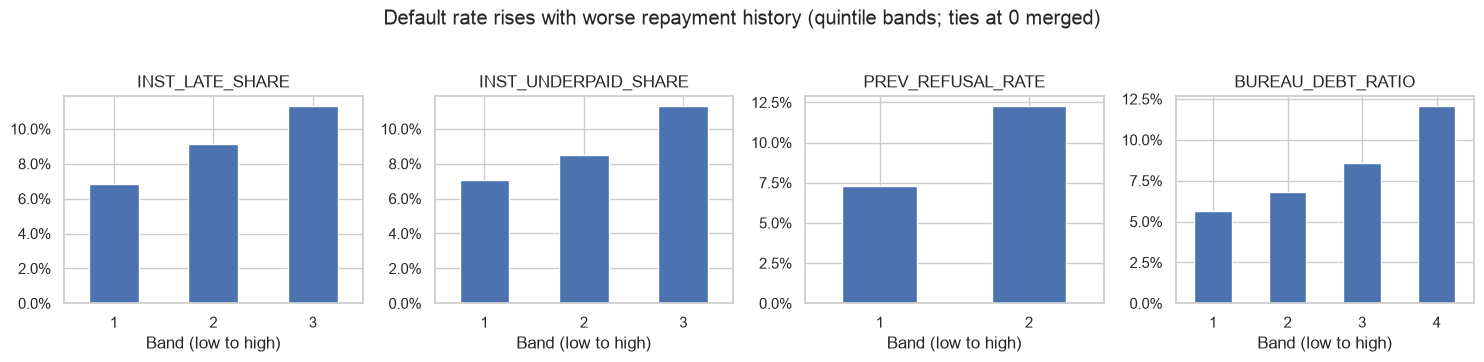

In [6]:
hist_cols = ["INST_LATE_SHARE", "INST_UNDERPAID_SHARE", "PREV_REFUSAL_RATE", "BUREAU_DEBT_RATIO"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, col in zip(axes, hist_cols):
    q = features[col].clip(features[col].quantile(0.01), features[col].quantile(0.99))
    rate = features.groupby(pd.qcut(q, 5, duplicates="drop"), observed=True)[TARGET_COL].mean()
    rate.plot.bar(ax=ax, color=PALETTE[0])
    ax.set_title(col); ax.set_xlabel("Band (low to high)"); ax.set_xticklabels(range(1, len(rate) + 1), rotation=0)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle("Default rate rises with worse repayment history (quintile bands; ties at 0 merged)", y=1.03)
savefig("08_history_behaviour")

In [7]:
FEATURES_PATH.parent.mkdir(parents=True, exist_ok=True)
features.to_parquet(FEATURES_PATH, index=False)
splits.to_parquet(SPLITS_PATH, index=False)
print("Saved", FEATURES_PATH.name, "and", SPLITS_PATH.name)

Saved features.parquet and splits.parquet
